In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
macro_econ_data = sm.datasets.macrodata.load_pandas().data
macro_econ_data.head()

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=2, dpi=300, figsize=(11,6))
for i, ax in enumerate(axes.flatten()[:6]):
    data = macro_econ_data[macro_econ_data.columns[i+2]]
    ax.plot(data)
    ax.set_title(macro_econ_data.columns[i+2])
    plt.setp(axes, xticks=np.arange(0, 208, 8), xticklabels=np.arange(1959, 2010, 2))
    fig.autofmt_xdate()
    plt.tight_layout()

In [ ]:
from statsmodels.tsa.statespace.varmax import VARMAX
from typing import Union
from tqdm import tqdm_notebook

def optimize_VAR(endog: Union[pd.Series, list]) -> pd.DataFrame:
	results = []
	for i in tqdm_notebook(range(15)):
		try:
			model = VARMAX(endog, order=(i, 0)).fit(disp=False)
		except:
			continue
		aic = model.aic
		results.append([i, aic])
  
	result_df = pd.DataFrame(results)
	result_df.columns = ['p', 'AIC']
	result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
	return result_df
         

In [ ]:
endog = macro_econ_data[['realdpi', 'realcons']]
endog_diff = macro_econ_data[['realdpi', 'realcons']].diff()[1:]

train = endog_diff[:162]
test = endog_diff[162:]

result_df = optimize_VAR(train)
result_df

In [ ]:
from statsmodels.tsa.stattools import grangercausalitytests
print('realcons Granger-causes realdpi?\n')
print('------------------')
granger_1 = grangercausalitytests(macro_econ_data[['realdpi', 'realcons']].diff()[1:], [3])

In [ ]:
print('\nrealdpi Granger-causes realcons?\n') 
print('------------------')
granger_2 = grangercausalitytests(macro_econ_data[['realcons', 'realdpi']].diff()[1:], [3])

In [25]:

best_model = VARMAX(train, order=(3,0))
best_model_fit = best_model.fit(disp=False)

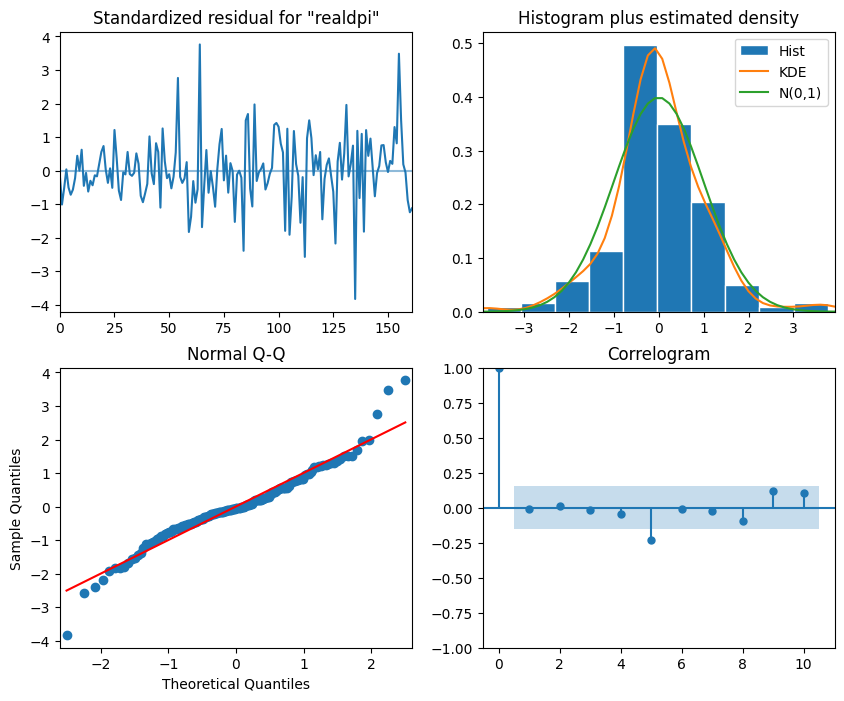

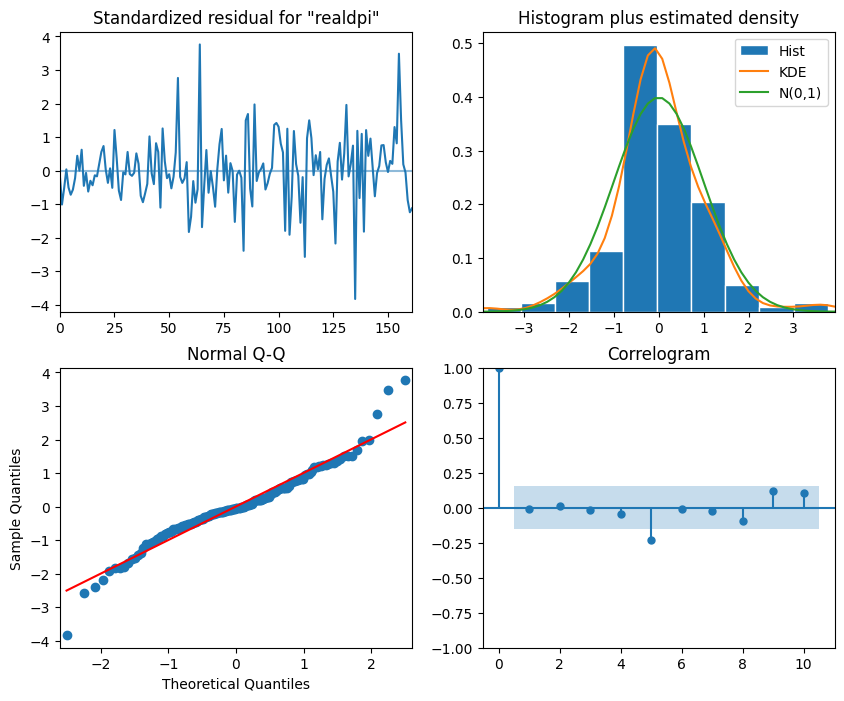

In [26]:
best_model_fit.plot_diagnostics(figsize=(10,8), variable=0)